<a href="https://colab.research.google.com/github/KwancheolShin/introduction-to-deep-learning/blob/main/%ED%8C%8C%EC%9D%B4%EC%8D%AC%EA%B8%B0%EC%B4%885.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 파이썬 기초 5: 딥러닝 코드를 위한 numpy

파이썬 기초 3에서 numpy 배열의 산술, N차원 배열, broadcasting, 원소 접근을 배웠다.
이 노트북은 수업의 NumPy 신경망 코드(`Affine`, `Relu`, `SoftmaxWithCrossEntropy`, `MultiLayerNet`, `im2col`)에 실제로 나오는 numpy 기능을 정리한다.

| 절 | 내용 | 수업 코드에서 쓰는 곳 |
|---|---|---|
| 30 | 행렬 곱과 전치: `@`, `np.dot`, `.T` | Affine 순전파·역전파 |
| 31 | 모양 바꾸기: `reshape`, `-1`, `flatten`, `transpose`, `None` | MNIST 펼치기, CNN의 im2col |
| 32 | view와 copy: slicing은 메모리를 공유한다 | 파이썬 기초 4의 참조·복사의 numpy 버전 |
| 33 | 인덱싱 심화: 정수 배열, one-hot, boolean mask, `argmax` | 미니배치, 정답 표현, ReLU, 정확도 |
| 34 | 난수: `seed`, `randn`, `permutation`, `rand` | 가중치 초기화, 데이터 섞기, dropout |
| 35 | 수치 계산에서 주의할 점: `exp`, `log`, `dtype`, `allclose` | softmax, cross-entropy, gradient 확인 |
| 36 | 집계와 비교: `np.max`와 `np.maximum`, `clip`, `where` | ReLU, 손실 계산 |
| 37 | CNN을 위한 배열: `(N, C, H, W)`, `np.pad`, im2col | 합성곱 층 |
| 38 | matplotlib 더 알아보기: `subplots`, `imshow` | 손실 곡선, 이미지와 필터 보기 |
| 39 | 반복문 대신 벡터 연산: 시간 재기 | 왜 numpy로 계산하는가 |
| 40 | 연습문제 | |

# 30. 행렬 곱과 전치

| 코드 | 뜻 |
|---|---|
| `A * B` | **같은 위치끼리** 곱 (원소별 곱, Hadamard product) |
| `A @ B`, `np.dot(A, B)` | **행렬 곱** |
| `A.T` | 전치 (행과 열을 바꿈) |

행렬 곱 `(m, k) @ (k, n)`은 가운데 `k`가 같아야 하고, 결과는 `(m, n)`이다.

In [1]:
import numpy as np

A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A * B =\n", A * B)
print("A @ B =\n", A @ B)
print("np.dot(A, B) == A @ B:", np.array_equal(np.dot(A, B), A @ B))
print("A.T =\n", A.T)

M = np.ones((2, 3))
try:
    M @ M                                   # (2,3) @ (2,3): 가운데 3과 2가 다르다
except ValueError as e:
    print("ValueError:", e)
print((M @ M.T).shape, (M.T @ M).shape)

A * B =
 [[ 5 12]
 [21 32]]
A @ B =
 [[19 22]
 [43 50]]
np.dot(A, B) == A @ B: True
A.T =
 [[1 3]
 [2 4]]
ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)
(2, 2) (3, 3)


## 30.1. Affine 층의 shape
미니배치 `X`가 `(N, 784)`, 가중치 `W`가 `(784, 50)`, bias `b`가 `(50,)`이면

* 순전파: `U = X @ W + b` → `(N, 784) @ (784, 50) = (N, 50)`, 그리고 `b`가 broadcasting으로 각 행에 더해진다.
* 역전파 (`dU`의 shape은 `U`와 같은 `(N, 50)`):
  * `dX = dU @ W.T` → `(N, 50) @ (50, 784) = (N, 784)`
  * `dW = X.T @ dU` → `(784, N) @ (N, 50) = (784, 50)`: `W`와 같은 shape
  * `db = dU.sum(axis=0)` → `(50,)`: 미니배치 방향으로 더한다

**gradient의 shape은 항상 그 parameter의 shape과 같다.** shape을 맞춰 보면 전치를 어디에 붙일지 알 수 있다.

In [2]:
N = 100
X  = np.random.randn(N, 784)
W  = np.random.randn(784, 50) * 0.01
b  = np.zeros(50)

U  = X @ W + b
dU = np.ones_like(U)                       # 위층에서 내려온 gradient라고 하자
dX = dU @ W.T
dW = X.T @ dU
db = dU.sum(axis=0)
for name, arr in [("X", X), ("W", W), ("b", b), ("U", U), ("dX", dX), ("dW", dW), ("db", db)]:
    print(f"{name:2s} {arr.shape}")

X  (100, 784)
W  (784, 50)
b  (50,)
U  (100, 50)
dX (100, 784)
dW (784, 50)
db (50,)


# 31. 모양 바꾸기

| 코드 | 하는 일 |
|---|---|
| `x.reshape(N, 784)` | 원소 수는 그대로 두고 shape만 바꾼다 |
| `x.reshape(N, -1)` | `-1`: 나머지 크기는 알아서 계산 |
| `x.flatten()` | 1차원으로 펼친 **복사본** |
| `x.ravel()` | 1차원으로 펼친다. 가능하면 **view** (32절) |
| `x.transpose(0, 2, 3, 1)` | 축의 순서를 바꾼다 (2차원의 `.T`를 일반화) |
| `x[:, None]`, `np.newaxis` | 크기 1인 축을 끼워 넣는다 |
| `x.squeeze()` | 크기 1인 축을 없앤다 |
| `np.concatenate`, `np.stack` | 배열 이어 붙이기 (있는 축 / 새 축) |

In [3]:
imgs = np.arange(2 * 28 * 28).reshape(2, 1, 28, 28)       # (N, C, H, W): 이미지 2장
flat = imgs.reshape(2, -1)                                # (2, 784): MLP에 넣을 모양
print(imgs.shape, "->", flat.shape)
print(flat.reshape(2, 1, 28, 28).shape)                   # 되돌리기
print(imgs.transpose(0, 2, 3, 1).shape)                   # (N, H, W, C): 채널을 맨 뒤로

v = np.array([1.0, 2.0, 3.0])
print(v.shape, v[None, :].shape, v[:, None].shape, v[:, None].squeeze().shape)

a, c = np.zeros((2, 3)), np.ones((2, 3))
print(np.concatenate([a, c], axis=0).shape, np.concatenate([a, c], axis=1).shape, np.stack([a, c]).shape)

try:
    np.arange(10).reshape(3, -1)                          # 10은 3으로 나누어떨어지지 않는다
except ValueError as e:
    print("ValueError:", e)

(2, 1, 28, 28) -> (2, 784)
(2, 1, 28, 28)
(2, 28, 28, 1)
(3,) (1, 3) (3, 1) (3,)
(4, 3) (2, 6) (2, 2, 3)
ValueError: cannot reshape array of size 10 into shape (3,newaxis)


# 32. view와 copy: slicing은 메모리를 공유한다

파이썬 기초 4에서 `b = a`는 같은 객체를 가리킨다는 것을 배웠다. numpy에는 한 가지가 더 있다.
**slicing(`a[1:3]`, `a[:, 0]`)과 `reshape`은 새 배열 객체를 만들지만, 숫자가 저장된 메모리는 원래 배열과 공유한다.** 이런 배열을 **view** 라고 한다.

| 결과가 view (메모리 공유) | 결과가 copy (새 메모리) |
|---|---|
| slicing `a[1:3]`, `a[:, 0]`, `a[::2]` | 정수 배열 인덱싱 `a[[0, 2]]` |
| `reshape` (대부분), `ravel` (가능하면), `.T`, `transpose` | boolean 인덱싱 `a[a > 0]` |
| | `flatten()`, `.copy()`, 산술 결과 `a + 1` |

`np.shares_memory(a, b)`로 메모리를 공유하는지 확인할 수 있다.

In [4]:
a = np.arange(6.)
s = a[1:4]                            # slicing -> view
print("s is a:", s is a, " shares memory:", np.shares_memory(a, s))
s[:] = 0                              # view를 고치면
print("a =", a)                       # 원래 배열도 바뀐다

a = np.arange(6.)
r = a.reshape(2, 3)                   # reshape -> view
r[0, 0] = 100
print("a =", a, " shares memory:", np.shares_memory(a, r))

a = np.arange(6.)
f = a[[0, 2, 4]]                      # 정수 배열 인덱싱 -> copy
f[:] = -1
print("a =", a, " shares memory:", np.shares_memory(a, f))

a = np.arange(6.)
c = a[1:4].copy()                     # 따로 쓰려면 .copy()
c[:] = 0
print("a =", a, " shares memory:", np.shares_memory(a, c))

s is a: False  shares memory: True
a = [0. 0. 0. 0. 4. 5.]
a = [100.   1.   2.   3.   4.   5.]  shares memory: True
a = [0. 1. 2. 3. 4. 5.]  shares memory: False
a = [0. 1. 2. 3. 4. 5.]  shares memory: False


**주의할 점**
* view에 **in-place 연산**(`s[:] = ...`, `s -= 1`, `s *= 0.5`)을 하면 원래 배열이 바뀐다.
* 반대로 `s = s - 1`은 새 배열을 만들어 이름만 옮기므로 원래 배열은 그대로이다 (파이썬 기초 4의 19절).
* 원래 배열을 지키고 싶으면 `.copy()`를 붙인다.

`x[mask] = 0`처럼 **대입하는 쪽**에 인덱싱을 쓰면, 인덱싱의 종류와 상관없이 원래 배열을 그 자리에서 고친다.

In [5]:
x = np.array([-2.0, -1.0, 0.5, 3.0])
x[x < 0] = 0                          # 대입: x 자체를 고친다
print(x)

[0.  0.  0.5 3. ]


# 33. 인덱싱 심화

## 33.1. 정수 배열로 여러 행 뽑기: 미니배치
`x[idx]`처럼 정수 배열(또는 list)로 인덱싱하면 그 번호의 행들을 순서대로 모은다.

In [6]:
x_train = np.arange(10 * 3).reshape(10, 3)           # 10개 데이터, 특징 3개
t_train = np.arange(10) % 3                           # 정답 class 0, 1, 2

np.random.seed(0)
perm = np.random.permutation(10)                      # 0..9를 섞은 순서
batch_size = 4
for it in range(10 // batch_size):
    idx = perm[it * batch_size:(it + 1) * batch_size]
    xb, tb = x_train[idx], t_train[idx]               # 같은 idx로 뽑아야 짝이 맞는다
    print(f"iteration {it}: idx {idx}, xb {xb.shape}, tb {tb}")

iteration 0: idx [2 8 4 9], xb (4, 3), tb [2 2 1 0]
iteration 1: idx [1 6 7 3], xb (4, 3), tb [1 0 1 0]


## 33.2. one-hot 표현과 class 번호
* class 번호 → one-hot: `np.eye(10)[t]`. 단위행렬의 `t`번째 행을 뽑는다.
* one-hot → class 번호: `np.argmax(T, axis=1)`

In [7]:
t = np.array([5, 0, 3])
T = np.eye(10)[t]                                     # (3, 10)
print(T)
print("back to labels:", np.argmax(T, axis=1))

[[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]]
back to labels: [5 0 3]


## 33.3. 예측과 정확도
점수(또는 확률) `Y`가 `(N, 10)`이면 `Y.argmax(axis=1)`이 각 행의 예측 class이다.
`pred == t`는 `True`/`False` 배열이고, `True`는 1로 계산되므로 `.sum()`은 맞힌 개수, `.mean()`은 정확도이다.

In [8]:
Y = np.array([[0.1, 0.7, 0.2],
              [0.8, 0.1, 0.1],
              [0.3, 0.3, 0.4],
              [0.2, 0.5, 0.3]])
t = np.array([1, 0, 1, 1])
pred = Y.argmax(axis=1)
print("pred:", pred, " correct:", pred == t)
print("count:", (pred == t).sum(), " accuracy:", (pred == t).mean())
print("dtype of pred == t:", (pred == t).dtype)

pred: [1 0 2 1]  correct: [ True  True False  True]
count: 3  accuracy: 0.75
dtype of pred == t: bool


## 33.4. boolean mask: ReLU의 순전파와 역전파
`mask = (x <= 0)`은 조건을 만족하는 위치가 `True`인 배열이다.
ReLU는 순전파에서 그 위치를 0으로 만들고, 역전파에서도 그 위치의 gradient를 0으로 만든다.

In [9]:
class Relu:
    def forward(self, x):
        self.mask = (x <= 0)              # 역전파 때 다시 쓰려고 저장
        out = x.copy()                    # 입력을 바꾸지 않으려고 복사 (32절)
        out[self.mask] = 0
        return out
    def backward(self, dout):
        dx = dout.copy()
        dx[self.mask] = 0                 # 순전파에서 0이 된 위치는 gradient도 0
        return dx

x = np.array([[1.0, -0.5], [-2.0, 3.0]])
relu = Relu()
print("forward :\n", relu.forward(x))
print("mask    :\n", relu.mask)
print("backward:\n", relu.backward(np.ones_like(x)))
print("x unchanged:\n", x)

forward :
 [[1. 0.]
 [0. 3.]]
mask    :
 [[False  True]
 [ True False]]
backward:
 [[1. 0.]
 [0. 1.]]
x unchanged:
 [[ 1.  -0.5]
 [-2.   3. ]]


# 34. 난수

| 코드 | 하는 일 | 수업 코드에서 |
|---|---|---|
| `np.random.seed(0)` | 난수의 출발점을 고정 → 매번 같은 결과 (재현성) | 실험을 다시 돌려도 같은 숫자 |
| `np.random.randn(m, n)` | 표준정규분포 $N(0,1)$ | 가중치 초기화 `std * randn(...)` |
| `np.random.rand(m, n)` | $[0, 1)$ 균등분포 | dropout mask `rand(...) > ratio` |
| `np.random.permutation(N)` | `0..N-1`을 섞은 순서 | epoch마다 데이터 섞기 |
| `np.random.choice(N, k)` | `0..N-1`에서 `k`개 뽑기 | 무작위 미니배치 |

In [10]:
np.random.seed(42); a = np.random.randn(3)
np.random.seed(42); b = np.random.randn(3)
print(a, b, "same:", np.array_equal(a, b))           # seed가 같으면 같은 난수

np.random.seed(0)
n_in = 784
W = np.sqrt(2.0 / n_in) * np.random.randn(n_in, 100)  # He 초기화
print("He std:", np.sqrt(2.0 / n_in).round(4), " sample std:", W.std().round(4))

x = np.ones((2, 5))
ratio = 0.4
mask = np.random.rand(*x.shape) > ratio               # 약 60%만 남긴다
print(mask)
print((x * mask / (1 - ratio)).round(3))              # inverted dropout: 남은 값을 키워 기댓값을 유지

[ 0.49671415 -0.1382643   0.64768854] [ 0.49671415 -0.1382643   0.64768854] same: True
He std: 0.0505  sample std: 0.0503
[[False  True  True  True False]
 [ True False  True False  True]]
[[0.    1.667 1.667 1.667 0.   ]
 [1.667 0.    1.667 0.    1.667]]


최근 numpy는 `rng = np.random.default_rng(0)`로 난수 생성기 객체를 만들어 `rng.normal(...)`, `rng.permutation(...)`처럼 쓰는 방식을 권장한다.
수업 코드는 짧고 익숙한 `np.random.seed` 방식을 쓴다.

# 35. 수치 계산에서 주의할 점

## 35.1. `exp`의 overflow
`np.exp(1000)`은 너무 커서 `inf`가 된다. softmax는 각 행에서 최댓값을 빼도 결과가 같으므로, 빼고 계산한다.

In [11]:
U = np.array([[1000.0, 1001.0, 1002.0]])
with np.errstate(over="ignore", invalid="ignore"):
    naive = np.exp(U) / np.exp(U).sum(axis=1, keepdims=True)
print("naive :", naive)                               # inf / inf = nan

V = U - U.max(axis=1, keepdims=True)                  # [-2, -1, 0]
print("stable:", (np.exp(V) / np.exp(V).sum(axis=1, keepdims=True)).round(4))

naive : [[nan nan nan]]
stable: [[0.09   0.2447 0.6652]]


## 35.2. `log(0)`과 작은 수 더하기
cross-entropy $-\sum_k t_k \log y_k$에서 $y_k = 0$이면 $\log 0 = -\infty$가 된다. 그래서 아주 작은 수를 더한다.

In [12]:
y = np.array([0.0, 1.0])
with np.errstate(divide="ignore"):
    print("log(y)       :", np.log(y))
print("log(y + 1e-7):", np.log(y + 1e-7).round(4))

def cross_entropy(Y, T):
    return -np.sum(T * np.log(Y + 1e-7)) / Y.shape[0]   # 미니배치 평균
print(cross_entropy(np.array([[0.1, 0.9], [0.8, 0.2]]), np.array([[0, 1], [1, 0]])).round(4))

log(y)       : [-inf   0.]
log(y + 1e-7): [-16.1181   0.    ]
0.1643


## 35.3. `dtype`: 정수와 실수, float32와 float64
* 정수 배열에 실수를 대입하면 **소수점 아래가 잘린다.** 실수 계산을 할 배열은 처음부터 float로 만든다.
* numpy의 기본 실수는 `float64`, PyTorch의 기본은 `float32`이다. `astype`으로 바꾼다.

In [13]:
a = np.array([1, 2, 3])
a[0] = 0.9                             # 정수 배열: 0으로 잘린다
print(a, a.dtype)
b = np.array([1.0, 2, 3])
b[0] = 0.9
print(b, b.dtype)

x = np.random.randn(3)
print(x.dtype, x.astype(np.float32).dtype, np.zeros(2).dtype, np.zeros(2, dtype=int).dtype)
print("float32 / float64 precision:", np.finfo(np.float32).eps, np.finfo(np.float64).eps)

[0 2 3] int64
[0.9 2.  3. ] float64
float64 float32 float64 int64
float32 / float64 precision: 1.1920929e-07 2.220446049250313e-16


## 35.4. 실수는 `==`가 아니라 `np.allclose`로 비교한다
실수 계산에는 반올림 오차가 있다. gradient 확인처럼 두 계산 결과를 비교할 때는 차이의 크기를 본다.

In [14]:
print(0.1 + 0.2 == 0.3, abs(0.1 + 0.2 - 0.3))
print(np.allclose(0.1 + 0.2, 0.3))

# gradient 확인: 수치 미분과 해석적 미분 비교 (f(w) = sum(w**2), df/dw = 2w)
def numerical_gradient(f, w, h=1e-4):
    g = np.zeros_like(w)
    for i in range(w.size):
        old = w.flat[i]
        w.flat[i] = old + h; fp = f(w)
        w.flat[i] = old - h; fm = f(w)
        w.flat[i] = old                    # 원래 값으로 되돌린다
        g.flat[i] = (fp - fm) / (2 * h)    # 중앙 차분
    return g

w = np.array([[1.0, -2.0], [0.5, 3.0]])
g_num = numerical_gradient(lambda w: np.sum(w ** 2), w)
g_ana = 2 * w
print("max abs diff:", np.abs(g_num - g_ana).max(), " allclose:", np.allclose(g_num, g_ana))

False 5.551115123125783e-17
True
max abs diff: 1.2661871551244985e-11  allclose: True


# 36. 집계와 비교

| 코드 | 하는 일 |
|---|---|
| `np.max(x)`, `x.max(axis=1)` | 배열 **안에서** 가장 큰 값 (집계, 축이 줄어든다) |
| `np.maximum(a, b)` | 두 배열을 **같은 위치끼리** 비교해 큰 값 (원소별, shape 유지) |
| `np.clip(x, lo, hi)` | `lo`보다 작으면 `lo`, `hi`보다 크면 `hi`로 |
| `np.where(cond, a, b)` | `cond`가 참인 곳은 `a`, 아닌 곳은 `b` |
| `x.sum()`, `x.mean()`, `x.std()`, `x.argmax()`, `x.argmin()` | 집계 (`axis`, `keepdims`는 파이썬 기초 4의 21절) |

In [15]:
x = np.array([-2.0, -0.5, 1.0, 3.0])
print("np.max(x)         :", np.max(x))
print("np.maximum(0, x)  :", np.maximum(0, x))          # ReLU를 한 줄로
print("np.clip(x, -1, 1) :", np.clip(x, -1, 1))
print("np.where(x > 0, x, 0.01 * x):", np.where(x > 0, x, 0.01 * x))   # leaky ReLU
print("argmax, argmin    :", x.argmax(), x.argmin())

np.max(x)         : 3.0
np.maximum(0, x)  : [0. 0. 1. 3.]
np.clip(x, -1, 1) : [-1.  -0.5  1.   1. ]
np.where(x > 0, x, 0.01 * x): [-0.02  -0.005  1.     3.   ]
argmax, argmin    : 3 0


# 37. CNN을 위한 배열

## 37.1. `(N, C, H, W)`와 `np.pad`
CNN의 입력은 4차원 배열 `(N, C, H, W)` = (이미지 수, 채널 수, 높이, 너비)이다.
패딩은 `np.pad`로 높이와 너비 축에만 0을 둘러싼다. 출력 크기는
$$H_{\text{out}} = \frac{H + 2P - F_H}{S} + 1, \qquad W_{\text{out}} = \frac{W + 2P - F_W}{S} + 1$$

In [16]:
x = np.arange(1, 10, dtype=float).reshape(1, 1, 3, 3)    # N=1, C=1, H=W=3
p = 1
xp = np.pad(x, [(0, 0), (0, 0), (p, p), (p, p)])         # 축마다 (앞, 뒤)에 붙일 칸 수
print(x.shape, "->", xp.shape)
print(xp[0, 0])

H, W, FH, FW, S, P = 28, 28, 5, 5, 1, 0
print("conv output:", (H + 2 * P - FH) // S + 1, "x", (W + 2 * P - FW) // S + 1)   # 24 x 24

(1, 1, 3, 3) -> (1, 1, 5, 5)
[[0. 0. 0. 0. 0.]
 [0. 1. 2. 3. 0.]
 [0. 4. 5. 6. 0.]
 [0. 7. 8. 9. 0.]
 [0. 0. 0. 0. 0.]]
conv output: 24 x 24


## 37.2. 합성곱을 반복문으로, 그리고 im2col로
합성곱은 필터를 밀면서 겹치는 부분끼리 곱해 더하는 계산이다. 반복문으로 쓰면 이해하기 쉽지만 느리다.
**im2col** 은 필터가 닿는 영역들을 한 행씩 펼쳐 큰 행렬로 만든 뒤, 합성곱을 **행렬 곱 한 번**으로 계산한다.

In [17]:
def conv2d_loop(img, k):
    H, W = img.shape; FH, FW = k.shape
    out = np.zeros((H - FH + 1, W - FW + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(img[i:i + FH, j:j + FW] * k)   # 겹치는 부분끼리 곱해 더한다
    return out

def conv2d_im2col(img, k):
    H, W = img.shape; FH, FW = k.shape
    OH, OW = H - FH + 1, W - FW + 1
    col = np.array([img[i:i + FH, j:j + FW].ravel()       # 영역 하나를 한 행으로 펼친다
                    for i in range(OH) for j in range(OW)])
    return (col @ k.ravel()).reshape(OH, OW), col.shape   # 행렬 곱 한 번

img = np.arange(16, dtype=float).reshape(4, 4)
k = np.array([[1.0, 0.0], [0.0, -1.0]])
out_loop = conv2d_loop(img, k)
out_col, col_shape = conv2d_im2col(img, k)
print(out_loop)
print("col shape:", col_shape, " same result:", np.allclose(out_loop, out_col))

[[-5. -5. -5.]
 [-5. -5. -5.]
 [-5. -5. -5.]]
col shape: (9, 4)  same result: True


수업의 `im2col`은 같은 일을 `(N, C, H, W)` 전체에 대해, 반복문을 필터 크기만큼만 돌도록 slicing과 `transpose`, `reshape`으로 구현한 것이다.

# 38. matplotlib 더 알아보기

## 38.1. `subplots`로 여러 그래프
`fig, ax = plt.subplots(1, 2)`는 그림(`fig`) 하나에 좌표축(`ax`) 두 개를 만든다. 그래프는 각 `ax`에 그린다.

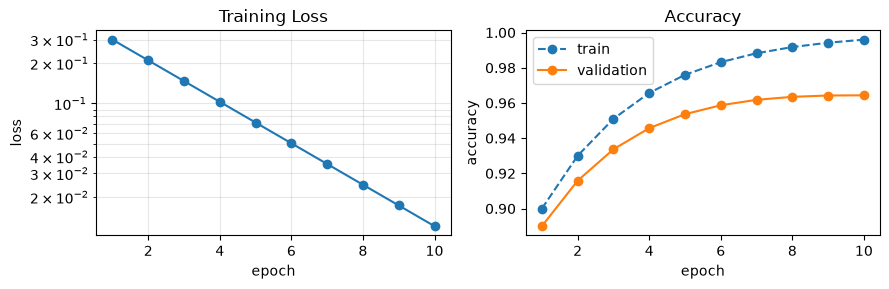

In [18]:
import matplotlib.pyplot as plt

epochs = np.arange(1, 11)
loss = 0.3 * 0.7 ** (epochs - 1)
train_acc = 1 - 0.1 * 0.7 ** (epochs - 1)
val_acc = train_acc - 0.01 * np.sqrt(epochs)              # 그림을 위한 가짜 값

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(epochs, loss, "o-")
ax[0].set_yscale("log")                                   # 손실은 로그 눈금이 보기 좋다
ax[0].set(xlabel="epoch", ylabel="loss", title="Training Loss")
ax[0].grid(True, which="both", alpha=0.3)
ax[1].plot(epochs, train_acc, "o--", label="train")
ax[1].plot(epochs, val_acc, "o-", label="validation")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
ax[1].legend()
fig.tight_layout()
plt.show()

## 38.2. `imshow`로 이미지 보기
scikit-learn에 들어 있는 작은 손글씨 숫자 데이터(8×8 픽셀)로 연습한다. MNIST(28×28)도 같은 방법으로 본다.

(1797, 8, 8) (1797,) 0.0 16.0


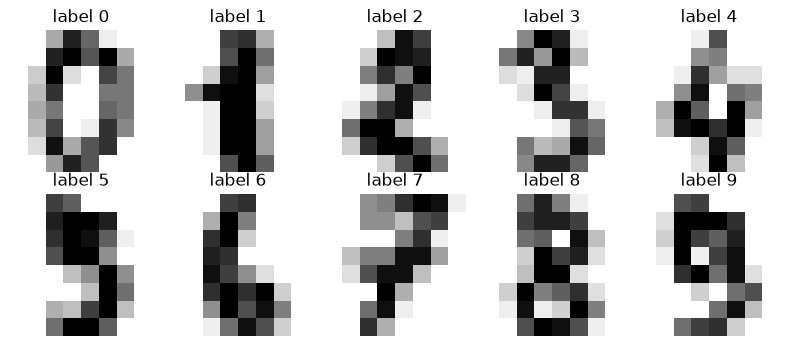

(1797, 64) (1797, 10) [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [19]:
from sklearn.datasets import load_digits

digits = load_digits()
X, t = digits.images, digits.target                       # (1797, 8, 8), (1797,)
print(X.shape, t.shape, X.min(), X.max())

fig, ax = plt.subplots(2, 5, figsize=(8, 3.5))
for i, a in enumerate(ax.ravel()):                        # 2x5 좌표축을 1차원으로 펼쳐 차례로
    a.imshow(X[i], cmap="gray_r")
    a.set_title(f"label {t[i]}")
    a.axis("off")
fig.tight_layout()
plt.show()

x_flat = X.reshape(len(X), -1) / 16.0                     # (1797, 64), 0..1로 정규화: MLP에 넣을 모양
T = np.eye(10)[t]                                         # one-hot (1797, 10)
print(x_flat.shape, T.shape, T[0])

그림을 파일로 저장하려면 `fig.savefig(경로)`를 쓰고, 화면에 띄우지 않을 때는 `plt.close(fig)`로 닫는다 (파이썬 기초 4의 25절).

# 39. 반복문 대신 벡터 연산

numpy의 연산은 내부에서 컴파일된 코드로 한꺼번에 계산되므로, 파이썬 `for` 문으로 원소를 하나씩 계산하는 것보다 훨씬 빠르다.
같은 행렬 곱을 두 방법으로 계산해 시간을 재 보자 (`time.perf_counter()`는 경과 시간을 재는 시계이다).

In [20]:
import time

np.random.seed(0)
A = np.random.randn(100, 200)
B = np.random.randn(200, 50)

t0 = time.perf_counter()
C_loop = np.zeros((100, 50))
for i in range(100):
    for j in range(50):
        s = 0.0
        for k in range(200):
            s += A[i, k] * B[k, j]
        C_loop[i, j] = s
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
C_vec = A @ B
t_vec = time.perf_counter() - t0

print(f"for loops: {t_loop:.3f} s,  A @ B: {t_vec * 1e3:.3f} ms,  same: {np.allclose(C_loop, C_vec)}")
print(f"about {t_loop / t_vec:,.0f} times faster")

for loops: 1.169 s,  A @ B: 0.726 ms,  same: True
about 1,609 times faster


시간은 컴퓨터마다 다르지만, 차이는 보통 수백 배에서 수천 배이다. 그래서 신경망 코드는 미니배치 전체를 행렬 곱 한 번으로 계산하도록 짠다.

# 40. 연습문제

1. `X`가 `(32, 100)`, `W`가 `(100, 10)`일 때 `X @ W`, `X.T`, `dU @ W.T` (`dU`는 `(32, 10)`), `X.T @ dU`의 shape을 쓰라.
2. `imgs`의 shape이 `(64, 1, 28, 28)`이다. `imgs.reshape(64, -1)`의 shape은? `imgs.transpose(0, 2, 3, 1)`의 shape은?
3. 다음 코드를 실행하면 `a`는 어떻게 되는가? `a[:2].copy()`로 바꾸면?
   ```python
   a = np.arange(5.)
   b = a[:2]
   b *= 10
   ```
4. 정답 `t = np.array([2, 0, 1])`을 one-hot으로 바꾸고, 다시 class 번호로 되돌리는 코드를 쓰라.
5. 점수 `Y`가 `(N, 10)`, 정답 class `t`가 `(N,)`일 때 정확도를 한 줄로 계산하라.
6. `x = np.array([-1.0, 2.0, -3.0, 4.0])`에 대하여 `np.max(x)`와 `np.maximum(0, x)`의 결과를 쓰고 차이를 설명하라.
7. `np.random.seed(0)` 뒤에 `np.random.permutation(5)`를 두 번 실행하면 두 결과가 같은가? 각 실행 바로 앞에 `seed(0)`을 넣으면?
8. `(1, 1, 28, 28)` 입력에 패딩 2, 필터 5×5, stride 1의 합성곱을 하면 출력의 높이와 너비는? `np.pad`로 패딩한 배열의 shape은?

In [21]:
# 연습문제 풀이 공간